### K-Means

In [1]:
import numpy as np

class KMeansScratch:
    def __init__(self, k=3, max_iters=100):
        self.k = k
        self.max_iters = max_iters
        self.centroids = None
    
    def fit(self, X):
        n_samples, n_features = X.shape
        
        # Step 1: randomly choose K points as the starting centroids
        random_indices = np.random.choice(n_samples, self.k, replace=False)
        self.centroids = X[random_indices]
        
        for iteration in range(self.max_iters):
            # Step 2: find the nearest centroid for each point
            # Hint: for each point, calculate the distance to all centroids, then use argmin()
            labels = self._assign_clusters(X)
            
            # Step 3: calculate the new centroids (the mean of each cluster)
            new_centroids = np.array([X[labels == i].mean(axis=0) for i in range(self.k)])
            
            # Convergence check: stop if the centroids barely move
            if np.allclose(self.centroids, new_centroids):
                break
            
            self.centroids = new_centroids
        
        self.labels_ = labels
    
    def _assign_clusters(self, X):
        # Calculate each point's distance to EVERY centroid
        distances = np.zeros((X.shape[0], self.k))
        for i, centroid in enumerate(self.centroids):
            distances[:, i] = np.sqrt(np.sum((X - centroid)**2, axis=1))
        
        # Step 4: for each point, return the index of the centroid with the MINIMUM distance
        return np.argmin(distances, axis=1)  # hint: np.argmin(distances, axis=1)
    
    def predict(self, X):
        return self._assign_clusters(X)

In [2]:
np.random.seed(42)
cluster1 = np.random.normal(loc=[2,2], scale=0.5, size=(50,2))
cluster2 = np.random.normal(loc=[8,8], scale=0.5, size=(50,2))
cluster3 = np.random.normal(loc=[2,8], scale=0.5, size=(50,2))
X = np.vstack([cluster1, cluster2, cluster3])

np.random.seed(1)
model = KMeansScratch(k=3)
model.fit(X)

print("Final centroids:")
print(model.centroids)
print(f"\nTrue centers were approximately: [2,2], [8,8], [2,8]")
print(f"\nCluster sizes: {np.bincount(model.labels_)}")

Final centroids:
[[1.93216218 1.9639913 ]
 [2.06447338 8.00042288]
 [7.95227356 8.07003103]]

True centers were approximately: [2,2], [8,8], [2,8]

Cluster sizes: [50 50 50]


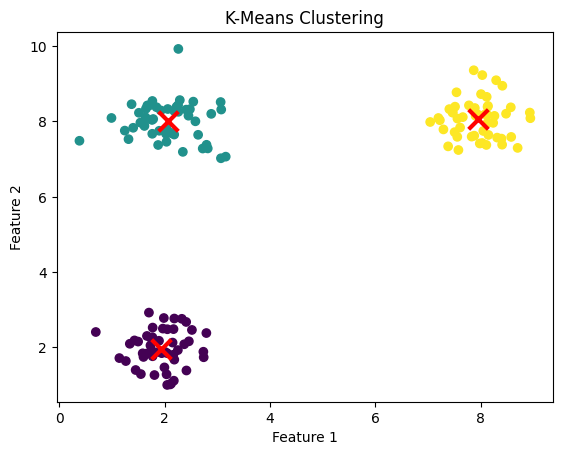

In [3]:
import matplotlib.pyplot as plt

plt.scatter(X[:, 0], X[:, 1], c=model.predict(X), cmap='viridis')
plt.scatter(model.centroids[:, 0], model.centroids[:, 1], c='red', marker='x', s=200, linewidths=3)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('K-Means Clustering')
plt.show()

In [4]:
import plotly.express as px
fig = px.scatter(x=X[:, 0], y=X[:, 1], color=model.predict(X).astype(str), title="K-Means Clustering with Plotly", labels={'x': 'Feature 1', 'y': 'Feature 2', 'color': 'Cluster'})
fig.add_scatter(x=model.centroids[:, 0], y=model.centroids[:, 1 ], mode='markers', marker=dict(color='red', size=12, symbol='x'), name='Centroids')


In [7]:

from sklearn.cluster import KMeans

for k in [1, 2, 3, 4, 5, 6, 8, 10]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    print(f"K={k}: WCSS (inertia) = {km.inertia_:.2f}")

K=1: WCSS (inertia) = 2482.42
K=2: WCSS (inertia) = 938.32
K=3: WCSS (inertia) = 71.55
K=4: WCSS (inertia) = 61.11
K=5: WCSS (inertia) = 53.01
K=6: WCSS (inertia) = 45.23
K=8: WCSS (inertia) = 33.94
K=10: WCSS (inertia) = 26.35


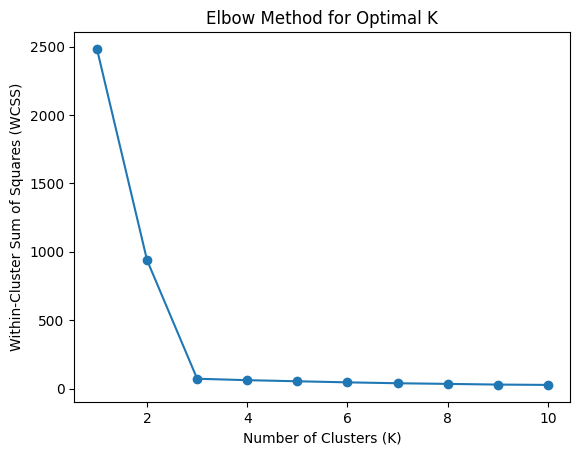

In [8]:
wcss_values = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    wcss_values.append(km.inertia_)

# Then plot K vs WCSS and identify the "elbow" visually
plt.plot(range(1, 11), wcss_values, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.title('Elbow Method for Optimal K')
plt.show()

In [ ]:

from sklearn.metrics import silhouette_score

for k in [2, 3, 4, 5, 6, 8]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    score = silhouette_score(X, labels)
    print(f"K={k}: Silhouette Score = {score:.4f}, WCSS = {km.inertia_:.2f}")

K=2: Silhouette Score = 0.6393, WCSS = 938.32
K=3: Silhouette Score = 0.8512, WCSS = 71.55
K=4: Silhouette Score = 0.6789, WCSS = 61.11
K=5: Silhouette Score = 0.5021, WCSS = 53.01
K=6: Silhouette Score = 0.3252, WCSS = 45.23
K=8: Silhouette Score = 0.3605, WCSS = 33.94


In [10]:
scores = []
for k in range(2, 11):  # the silhouette score cannot be calculated for K=1 (at least 2 clusters are needed)
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    scores.append(silhouette_score(X, labels))

best_k = range(2,11)[np.argmax(scores)]   # the best K is where the score is maximum

In [1]:
import numpy as np

np.random.seed(25)
n_customers = 300

annual_spend = np.concatenate([
    np.random.normal(20000, 5000, 100),   # budget shoppers
    np.random.normal(60000, 8000, 100),   # mid-range
    np.random.normal(120000, 15000, 100)  # premium
])
visit_frequency = np.concatenate([
    np.random.normal(5, 2, 100),
    np.random.normal(15, 3, 100),
    np.random.normal(8, 2, 100)
])

X = np.column_stack([annual_spend, visit_frequency])
np.random.shuffle(X)

In [2]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X_scaled)
labels = kmeans.labels_
print(kmeans.cluster_centers_)

[[ 1.25139294 -0.29074476]
 [-1.04317571 -0.85458455]
 [-0.17933231  1.2669851 ]]


#### GMM - Gaussian Mixture Models

In [4]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=3, random_state=42)  # 'n_components' is the equivalent of K in K-Means
gmm.fit(X_scaled)

labels = gmm.predict(X_scaled)           # hard cluster labels (if needed)
probabilities = gmm.predict_proba(X_scaled)  # SOFT probabilities: a unique feature of GMM

print(probabilities[:5])  # print the probabilities for the first 5 customers

[[9.36611516e-06 3.33947660e-24 9.99990634e-01]
 [1.00000000e+00 1.68630604e-85 1.88144997e-13]
 [9.99997719e-01 4.79138543e-55 2.28089881e-06]
 [1.61397440e-10 9.99999184e-01 8.15907198e-07]
 [1.00000000e+00 1.11502633e-74 8.39483208e-11]]


#### Hierarchical Clustering

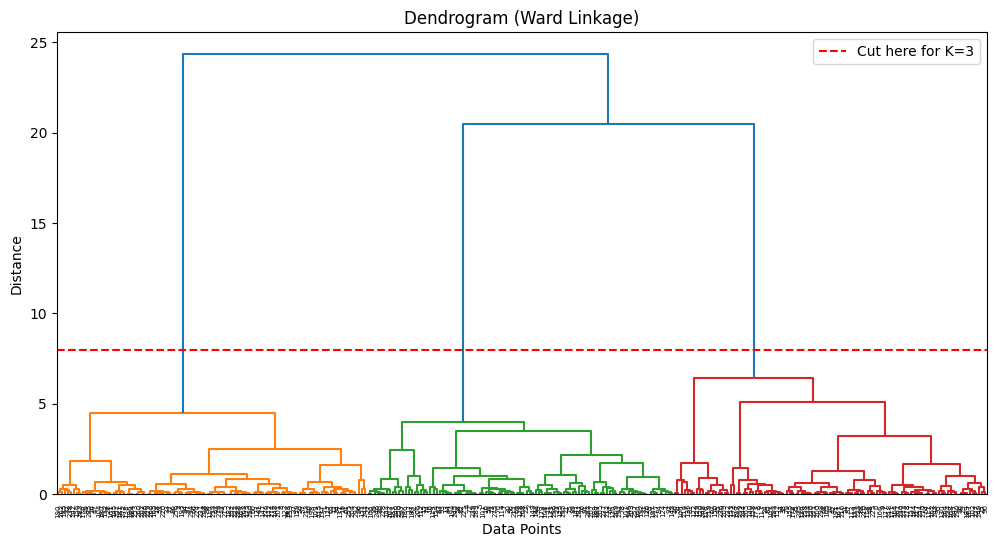

In [12]:
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

# Build the linkage matrix
Z = linkage(X_scaled, method='ward')  # you can also try 'single', 'complete', 'average'


plt.figure(figsize=(12, 6))
dendrogram(Z)
plt.title("Dendrogram (Ward Linkage)")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.axhline(y=8, color='r', linestyle='--', label='Cut here for K=3')
plt.legend()
plt.show()

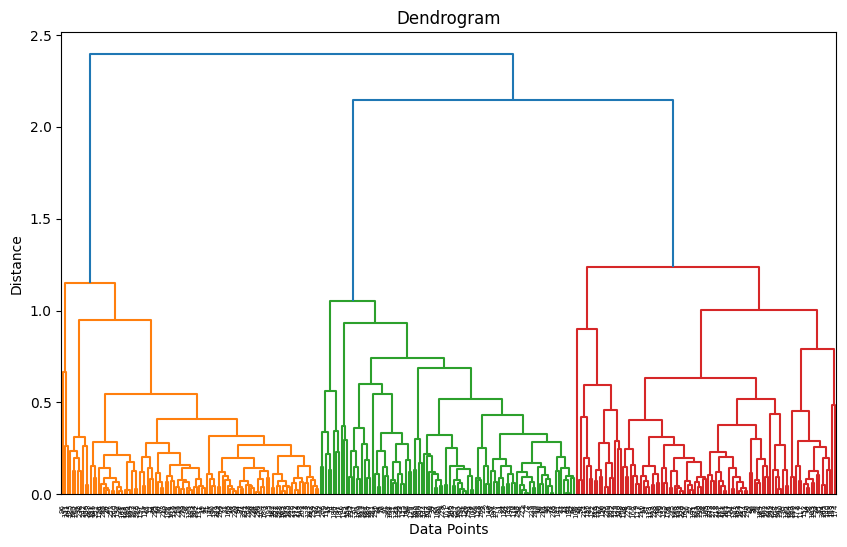

In [6]:
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

# Build the linkage matrix
Z = linkage(X_scaled, method='average')  # you can also try 'single', 'complete', 'average'

plt.figure(figsize=(10, 6))
dendrogram(Z)
plt.title("Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

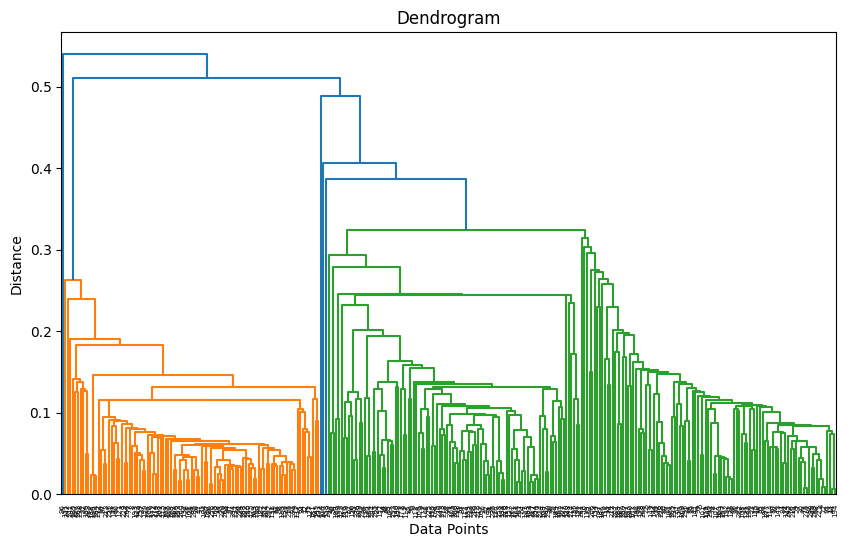

In [7]:
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

# Build the linkage matrix
Z = linkage(X_scaled, method='single')  # you can also try 'single', 'complete', 'average'

plt.figure(figsize=(10, 6))
dendrogram(Z)
plt.title("Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

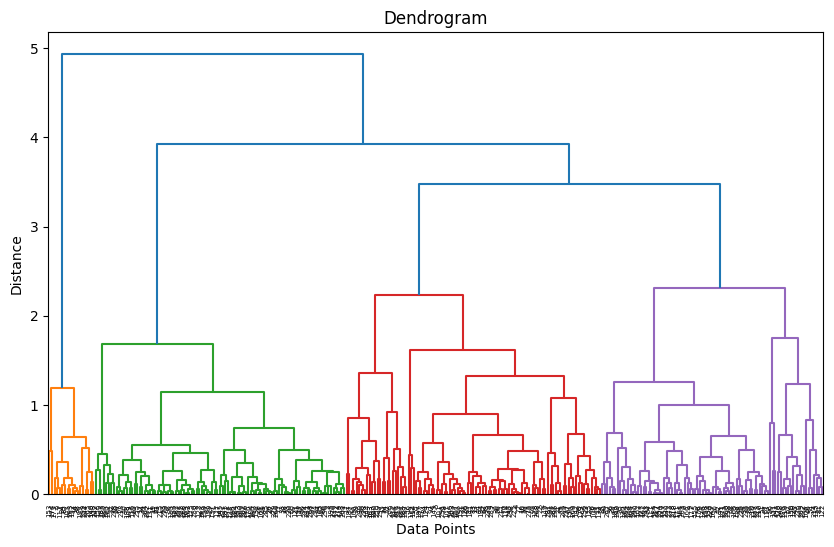

In [8]:
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

# Build the linkage matrix
Z = linkage(X_scaled, method='complete')  # you can also try 'single', 'complete', 'average'

plt.figure(figsize=(10, 6))
dendrogram(Z)
plt.title("Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

In [9]:
from scipy.cluster.hierarchy import fcluster

# "Cut" the dendrogram to get K=3 clusters
labels = fcluster(Z, t=3, criterion='maxclust')

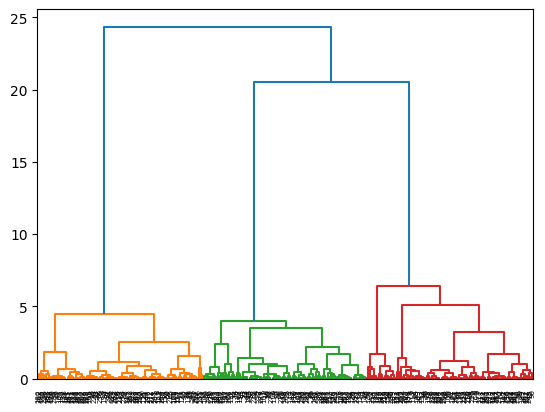

[3 2 2 1 2 2 3 2 1 3 2 2 1 2 3 2 2 2 1 1 3 2 2 2 3 3 1 2 1 3 2 2 1 1 1 3 3
 1 3 2 1 1 3 1 2 3 3 1 3 1 1 3 2 1 3 2 2 1 2 2 1 1 3 1 3 1 1 2 3 2 2 1 2 2
 2 2 2 1 2 3 2 3 2 2 2 3 1 3 3 2 3 2 2 2 1 3 1 1 1 2 2 2 3 3 1 3 3 2 2 1 1
 3 2 3 2 1 3 3 3 2 3 1 3 1 2 2 2 1 2 3 3 1 1 2 3 3 3 1 1 3 3 2 2 2 2 1 2 1
 1 2 3 1 3 3 2 3 1 3 3 1 2 1 3 2 3 1 3 3 3 1 2 3 1 3 3 1 1 3 3 2 1 1 1 2 3
 1 2 2 2 3 1 3 2 1 2 1 1 2 1 3 3 1 1 2 1 2 2 2 2 3 3 2 2 1 3 1 3 3 3 3 1 2
 1 3 1 3 3 3 2 1 3 1 3 1 3 3 3 2 1 2 2 1 1 3 3 2 2 3 3 3 2 1 1 1 3 1 1 2 3
 1 1 3 1 1 3 3 1 3 1 2 3 3 1 3 1 2 1 2 3 1 1 2 2 1 1 1 1 2 1 2 3 2 1 3 1 2
 2 2 3 3]


In [10]:
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
import matplotlib.pyplot as plt

# Step 1: build the full hierarchy
Z = linkage(X_scaled, method='ward')

# Step 2: look at the dendrogram and decide K=3 (visually)
dendrogram(Z)
plt.show()

# Step 3: "cut" the dendrogram at K=3. This is the FINAL MODEL/RESULT!
labels = fcluster(Z, t=3, criterion='maxclust')

# 'labels' now holds the FINAL CLUSTER ASSIGNMENT of EVERY POINT. Done!
print(labels)  # e.g. [1, 1, 2, 3, 1, 2, 2, 3, ...]

In [11]:
from sklearn.cluster import AgglomerativeClustering

model = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels = model.fit_predict(X_scaled)   # works just like KMeans().fit_predict()!

#### DBSCAN

In [1]:
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
cluster1 = np.random.normal(loc=[2,2], scale=0.5, size=(30,2))
cluster2 = np.random.normal(loc=[8,8], scale=0.5, size=(30,2))
cluster3 = np.random.normal(loc=[2,8], scale=0.5, size=(30,2))
X = np.vstack([cluster1, cluster2, cluster3])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

for eps in [0.1, 0.3, 0.5, 1.0, 3.0]:
    db = DBSCAN(eps=eps, min_samples=5)
    labels = db.fit_predict(X_scaled)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    print(f"eps={eps}: clusters found={n_clusters}, noise points={n_noise}")

eps=0.1: clusters found=4, noise points=53
eps=0.3: clusters found=3, noise points=0
eps=0.5: clusters found=3, noise points=0
eps=1.0: clusters found=3, noise points=0
eps=3.0: clusters found=1, noise points=0


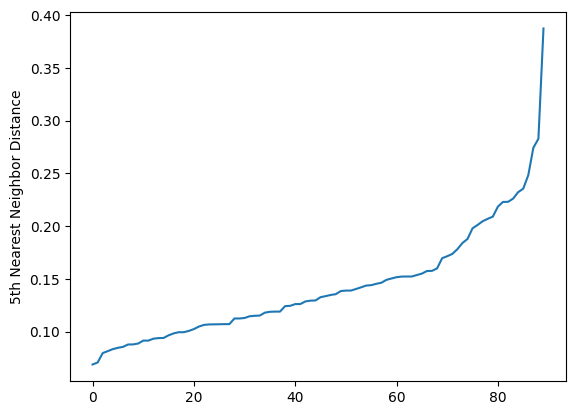

In [3]:
from matplotlib import pyplot as plt
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=5)  # equal to min_samples
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

distances = np.sort(distances[:, -1])  # distance to each point's 5th-nearest neighbour
plt.plot(distances)
plt.ylabel("5th Nearest Neighbor Distance")
plt.show()
# Where the curve shows an "elbow/bend" is a good eps (just like the Elbow Method!)

In [3]:
# From Scartch Impelementation of DBSCAN
import numpy as np

class DBSCANScratch:
    def __init__(self, eps=0.5, min_samples=5):
        self.eps = eps
        self.min_samples = min_samples
    
    def fit_predict(self, X):
        n_samples = X.shape[0]
        labels = np.full(n_samples, -2)  # -2 = "not visited yet"
        cluster_id = 0
        
        for point_idx in range(n_samples):
            if labels[point_idx] != -2:
                continue  # already processed
            
            neighbors = self._get_neighbors(X, point_idx)
            
            if len(neighbors) < self.min_samples:
                labels[point_idx] = -1  # Noise (for now; it may become a border point later)
            else:
                # Start a new cluster and expand all reachable points
                self._expand_cluster(X, labels, point_idx, neighbors, cluster_id)
                cluster_id += 1
        
        return labels
    
    def _get_neighbors(self, X, point_idx):
        distances = np.sqrt(np.sum((X - X[point_idx])**2, axis=1))
        return np.where(distances <= self.eps)[0]
    
    def _expand_cluster(self, X, labels, point_idx, neighbors, cluster_id):
        labels[point_idx] = cluster_id
        
        i = 0
        neighbors = list(neighbors)
        while i < len(neighbors):
            neighbor_idx = neighbors[i]
            
            if labels[neighbor_idx] == -1:  # was Noise before, is now a Border Point
                labels[neighbor_idx] = cluster_id
            
            if labels[neighbor_idx] == -2:  # not visited yet
                labels[neighbor_idx] = cluster_id
                new_neighbors = self._get_neighbors(X, neighbor_idx)
                
                if len(new_neighbors) >= self.min_samples:
                    # This is also a core point: add its neighbours to the exploration
                    neighbors += list(new_neighbors)
            
            i += 1

In [4]:
import numpy as np

np.random.seed(42)
cluster1 = np.random.normal(loc=[2,2], scale=0.5, size=(30,2))
cluster2 = np.random.normal(loc=[8,8], scale=0.5, size=(30,2))
cluster3 = np.random.normal(loc=[2,8], scale=0.5, size=(30,2))
X = np.vstack([cluster1, cluster2, cluster3])

In [5]:
from sklearn.preprocessing import StandardScaler
X_scaled = StandardScaler().fit_transform(X)

dbscan = DBSCANScratch(eps=0.5, min_samples=5)
labels = dbscan.fit_predict(X_scaled)

print(f"Clusters found: {len(set(labels)) - (1 if -1 in labels else 0)}")
print(f"Noise points: {list(labels).count(-1)}")

# Compare with scikit-learn
from sklearn.cluster import DBSCAN
sklearn_db = DBSCAN(eps=0.5, min_samples=5)
sklearn_labels = sklearn_db.fit_predict(X_scaled)
print(f"\nsklearn - Clusters: {len(set(sklearn_labels)) - (1 if -1 in sklearn_labels else 0)}")
print(f"sklearn - Noise: {list(sklearn_labels).count(-1)}")

Clusters found: 3
Noise points: 0

sklearn - Clusters: 3
sklearn - Noise: 0


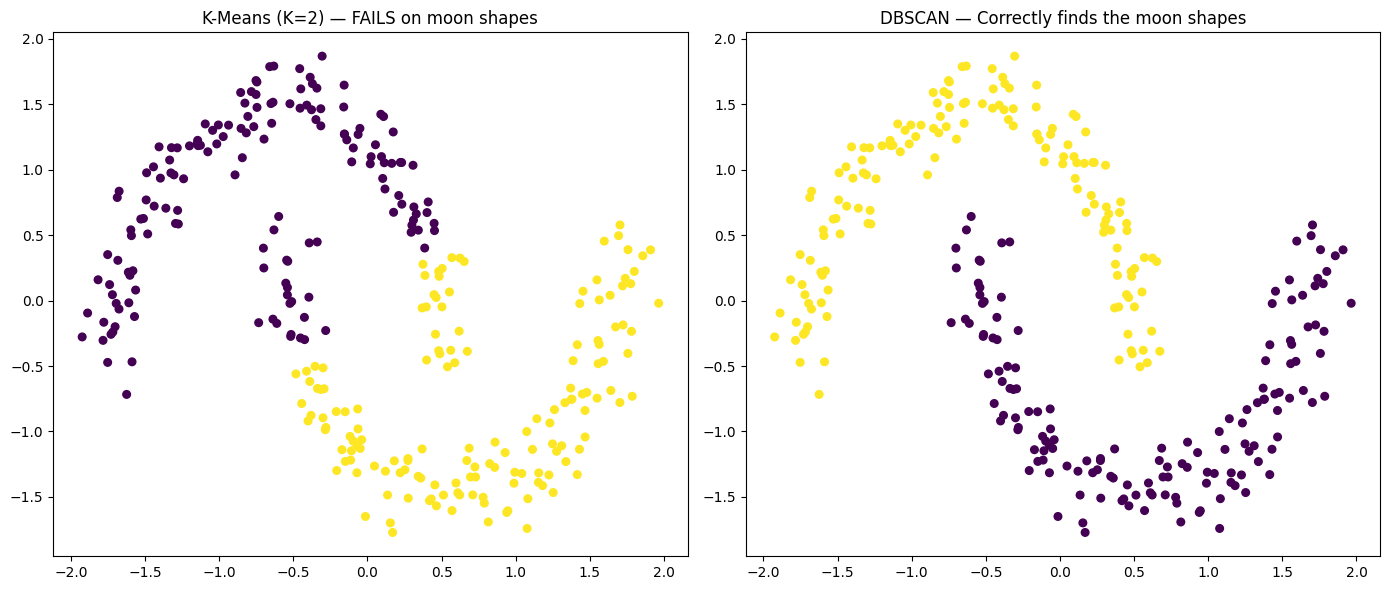

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler

X, y_true = make_moons(n_samples=300, noise=0.08, random_state=42)
X_scaled = StandardScaler().fit_transform(X)

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

dbscan = DBSCAN(eps=0.3, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(X_scaled[:,0], X_scaled[:,1], c=kmeans_labels, cmap='viridis', s=30)
axes[0].set_title("K-Means (K=2) — FAILS on moon shapes")

axes[1].scatter(X_scaled[:,0], X_scaled[:,1], c=dbscan_labels, cmap='viridis', s=30)
axes[1].set_title("DBSCAN — Correctly finds the moon shapes")

plt.tight_layout()

### Dimensionality Reduction Algorithms

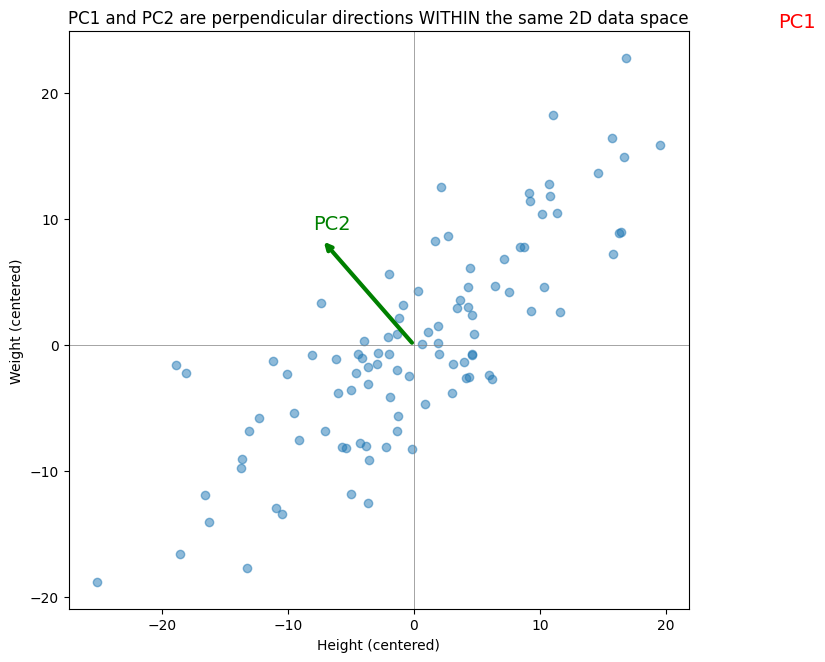

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

np.random.seed(42)
# Correlated data: height and weight
height = np.random.normal(170, 10, 100)
weight = height * 0.8 + np.random.normal(0, 5, 100) - 50

X = np.column_stack([height, weight])
X_centered = X - X.mean(axis=0)

pca = PCA(n_components=2)
pca.fit(X_centered)

fig, ax = plt.subplots(figsize=(8,8))
ax.scatter(X_centered[:,0], X_centered[:,1], alpha=0.5, label='Data points')

# Draw PC1 and PC2 directions from origin, scaled by their explained variance
origin = [0,0]
for i, (comp, var) in enumerate(zip(pca.components_, pca.explained_variance_)):
    scale = np.sqrt(var) * 3
    ax.annotate('', xy=(comp[0]*scale, comp[1]*scale), xytext=origin,
                arrowprops=dict(arrowstyle='->', color='red' if i==0 else 'green', lw=3))
    ax.text(comp[0]*scale*1.1, comp[1]*scale*1.1, f'PC{i+1}', fontsize=14, color='red' if i==0 else 'green')

ax.set_xlabel('Height (centered)')
ax.set_ylabel('Weight (centered)')
ax.set_title('PC1 and PC2 are perpendicular directions WITHIN the same 2D data space')
ax.axhline(0, color='gray', lw=0.5)
ax.axvline(0, color='gray', lw=0.5)
ax.set_aspect('equal')

In [2]:
import numpy as np
from sklearn.decomposition import PCA

np.random.seed(42)

# Scenario 1: CORRELATED features (height, weight)
height = np.random.normal(170, 10, 200)
weight = height * 0.8 + np.random.normal(0, 5, 200) - 50
X_correlated = np.column_stack([height, weight])

pca1 = PCA(n_components=2)
pca1.fit(X_correlated)
print("CORRELATED features (height, weight):")
print(f"  PC1 explains: {pca1.explained_variance_ratio_[0]*100:.1f}% variance")
print(f"  PC2 explains: {pca1.explained_variance_ratio_[1]*100:.1f}% variance")

# Scenario 2: INDEPENDENT features (random, uncorrelated)
feature_A = np.random.normal(50, 10, 200)  # e.g., "favorite color" encoded randomly
feature_B = np.random.normal(8, 2, 200)     # e.g., "shoe size" - no relation to A
X_independent = np.column_stack([feature_A, feature_B])

pca2 = PCA(n_components=2)
pca2.fit(X_independent)
print("\nINDEPENDENT features (no correlation):")
print(f"  PC1 explains: {pca2.explained_variance_ratio_[0]*100:.1f}% variance")
print(f"  PC2 explains: {pca2.explained_variance_ratio_[1]*100:.1f}% variance")

CORRELATED features (height, weight):
  PC1 explains: 92.5% variance
  PC2 explains: 7.5% variance

INDEPENDENT features (no correlation):
  PC1 explains: 96.0% variance
  PC2 explains: 4.0% variance


In [3]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

# Scenario 2: INDEPENDENT features, but SAME scale/variance (fair comparison)
feature_A = np.random.normal(50, 10, 200)
feature_B = np.random.normal(8, 10, 200)   # SAME std=10 now, still no relation to A
X_independent = np.column_stack([feature_A, feature_B])

# Verify they're genuinely uncorrelated
correlation = np.corrcoef(feature_A, feature_B)[0,1]
print(f"Correlation between feature_A and feature_B: {correlation:.4f}  (should be ~0)")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_independent)

pca = PCA(n_components=2)
pca.fit(X_scaled)
print(f"\nINDEPENDENT features (same scale, no correlation):")
print(f"  PC1 explains: {pca.explained_variance_ratio_[0]*100:.1f}% variance")
print(f"  PC2 explains: {pca.explained_variance_ratio_[1]*100:.1f}% variance")

Correlation between feature_A and feature_B: 0.0951  (should be ~0)

INDEPENDENT features (same scale, no correlation):
  PC1 explains: 54.8% variance
  PC2 explains: 45.2% variance


In [3]:
# From Scratch
import numpy as np

class PCAScratch:
    def __init__(self, n_components):
        self.n_components = n_components
        self.components = None
        self.mean = None
        self.explained_variance_ratio = None
    
    def fit(self, X):
        # Step 1: "centre" the data (subtract the mean; PCA needs origin-centred data)
        self.mean = np.mean(X, axis=0)
        X_centered = X - self.mean
        
        # Step 2: build the covariance matrix, which shows the relationship between every pair of features
        cov_matrix = np.cov(X_centered.T)
        
        # Step 3: calculate the eigenvalues and eigenvectors
        # Eigenvectors = "directions" (PCs), Eigenvalues = "how much variance lies in that direction"
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
        
        # Step 4: sort the eigenvalues in DESCENDING order (highest variance FIRST)
        sorted_idx = np.argsort(eigenvalues)[::-1]
        eigenvalues = eigenvalues[sorted_idx]
        eigenvectors = eigenvectors[:, sorted_idx]
        
        # Step 5: keep only the top 'n_components'
        self.components = eigenvectors[:, :self.n_components]
        
        total_variance = np.sum(eigenvalues)
        self.explained_variance_ratio = eigenvalues[:self.n_components] / total_variance
    
    def transform(self, X):
        X_centered = X - self.mean
        return X_centered @ self.components   # "project" the data onto the new PC axes
    
    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)

In [4]:
import numpy as np
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
height = np.random.normal(170, 10, 200)
weight = height * 0.8 + np.random.normal(0, 5, 200) - 50
X = np.column_stack([height, weight])

X_scaled = StandardScaler().fit_transform(X)

pca_scratch = PCAScratch(n_components=2)
X_transformed = pca_scratch.fit_transform(X_scaled)

print("Explained variance ratio:", pca_scratch.explained_variance_ratio)

# Compare with scikit-learn
from sklearn.decomposition import PCA
pca_sklearn = PCA(n_components=2)
pca_sklearn.fit(X_scaled)
print("sklearn explained variance ratio:", pca_sklearn.explained_variance_ratio_)

Explained variance ratio: [0.9248617 0.0751383]
sklearn explained variance ratio: [0.9248617 0.0751383]


In [5]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
# 5 features, some correlated, some not - realistic example
n = 300
f1 = np.random.normal(50, 10, n)
f2 = f1 * 0.9 + np.random.normal(0, 3, n)   # correlated with f1
f3 = f1 * 0.7 + np.random.normal(0, 5, n)   # somewhat correlated with f1
f4 = np.random.normal(20, 5, n)             # independent
f5 = np.random.normal(100, 15, n)           # independent

X = np.column_stack([f1,f2,f3,f4,f5])
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=5)
pca.fit(X_scaled)

print("Individual explained variance per PC:")
for i, ratio in enumerate(pca.explained_variance_ratio_):
    print(f"  PC{i+1}: {ratio*100:.2f}%")

print("\nCumulative explained variance:")
cumulative = np.cumsum(pca.explained_variance_ratio_)
for i, c in enumerate(cumulative):
    print(f"  PC1 to PC{i+1}: {c*100:.2f}%")

Individual explained variance per PC:
  PC1: 53.67%
  PC2: 20.56%
  PC3: 19.33%
  PC4: 5.52%
  PC5: 0.92%

Cumulative explained variance:
  PC1 to PC1: 53.67%
  PC1 to PC2: 74.23%
  PC1 to PC3: 93.56%
  PC1 to PC4: 99.08%
  PC1 to PC5: 100.00%


In [6]:
# Practical code:
pca = PCA(n_components=0.95)   # "as many PCs as needed to reach 95% variance"
X_reduced = pca.fit_transform(X_scaled)
print(f"Components used: {pca.n_components_}")

Components used: 4


pca = PCA(n_components=0.95)
X_train_reduced = pca.fit_transform(X_train_scaled)   # fit + transform TRAINING pe
X_test_reduced = pca.transform(X_test_scaled)          # transform ONLY on the test set (no fit!)

model.fit(X_train_reduced, y_train)
model.score(X_test_reduced, y_test)